# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170095         # <-- your full roll number
NAME = "Rehmat Chawla"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170095   Name: Rehmat Chawla   Fingerprint: 2B64A48A   Tickets: 12

Ticket_ID                                                                                Ticket_Text
      T01           Student portal keeps asking for login when I use mobile hotspot. This is urgent.
      T02                I tried restarting the password since yesterday. I don't know what changed.
      T03  I tried restarting the Python before the assignment deadline. I have tried several times!
      T04                                                      Nothing works and nobody has replied.
      T05                                                            Is it fixed?? Pls reply ASAP :(
      T06                                      The MATLAB failed to open. I don't know what changed.
      T07 Python was working yesterday when connected to campus Wi-Fi. It works on another computer.
      T08           I cannot access the printer while uploading the file. I don't know what changed.
      

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
results = []
for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]
    processed = process_ticket(text)
    results.append({
        "Ticket_ID": ticket_id,
        "Sentences": processed["sentences"],
        "Tokens": processed["tokens"],
        "Punctuation": processed["punct"],
        "Stopwords": processed["stops"],
        "Unique": set(processed["tokens"]),
        "Final": processed["final"]
    })

# Convert to DataFrame
table = pd.DataFrame(results)

# Add TOTAL row
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": sum(len(r["Sentences"]) for r in results),
    "Tokens": sum(len(r["Tokens"]) for r in results),
    "Punctuation": sum(len(r["Punctuation"]) for r in results),
    "Stopwords": sum(len(r["Stopwords"]) for r in results),
    "Unique": set().union(*[r["Unique"] for r in results]),
    "Final": sum(len(r["Final"]) for r in results)
}
table = pd.concat([table, pd.DataFrame([total_row])], ignore_index=True)

print(table)


   Ticket_ID                                          Sentences  \
0        T01  [Student portal keeps asking for login when I ...   
1        T02  [I tried restarting the password since yesterd...   
2        T03  [I tried restarting the Python before the assi...   
3        T04            [Nothing works and nobody has replied.]   
4        T05                 [Is it fixed??, Pls reply ASAP :(]   
5        T06  [The MATLAB failed to open., I don't know what...   
6        T07  [Python was working yesterday when connected t...   
7        T08  [I cannot access the printer while uploading t...   
8        T09  [Student portal stopped responding after resta...   
9        T10  [Write to it.helpdesk@thapar.edu or visit www....   
10       T11                    [Version 2.0.1 crashes at 99%.]   
11       T12      [The WiFi keeps disconnecting., Please help.]   
12     TOTAL                                                 21   

                                               Tokens   Punct

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* In the final tokens, we observe non‑word fragments such as ‘n’t’, ‘’s’, and ‘ca’. These arise because the tokenizer splits contractions and possessives at apostrophes. For example, ‘can’t’ becomes ‘ca’ + ‘n’t’, and ‘it’s’ becomes ‘it’ + ‘’s’. Such tokens are not meaningful words on their own and are artifacts of the tokenization process


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
import re
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

for line in TEST_LINES:
    print("Line:", line)
    # Words longer than 5 letters
    print("Words >5 letters:", re.findall(r"\b[a-zA-Z]{6,}\b", line))
    # Numbers (keep decimals and versions whole)
    print("Numbers:", re.findall(r"\b\d+(?:\.\d+)*\b", line))
    # Capitalized words
    print("Capitalized:", re.findall(r"\b[A-Z][a-zA-Z]*\b", line))
    # Words starting with a vowel
    print("Starts with vowel:", re.findall(r"\b[AEIOUaeiou][a-zA-Z]*\b", line))
    print()

# Replace emails with comma
cleaned = [re.sub(r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}", ",", l) for l in TEST_LINES]
# Replace URLs with comma
cleaned = [re.sub(r"(https?://\S+|www\.\S+)", ",", l) for l in cleaned]
# Replace phone numbers with period
cleaned = [re.sub(r"\+?\d[\d\s-]{8,}\d", ".", l) for l in cleaned]

print("Cleaned lines:")
for c in cleaned:
    print(c)

Line: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Words >5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized: ['Mail']
Starts with vowel: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

Line: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Words >5 letters: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized: ['Call', 'Version', 'Rs']
Starts with vowel: ['or', 'is']

Line: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Words >5 letters: []
Numbers: ['5.30']
Capitalized: ['The']
Starts with vowel: ['of', 'art', 'isn', 'open', 'in', 'at']

Cleaned lines:
Mail , or ,; visit , or ,
Call ., . or .. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*Among the capitalized words, some like ‘Mail’, ‘Call’, and ‘Version’ are genuine proper nouns or terms. Others, such as ‘The’, are capitalized only because they occur at the beginning of a sentence


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Your code
for i, text in enumerate(df["Ticket_Text"], start=1):
    my_toks = my_tokenize(text)
    word_toks = word_tokenize(text)
    if my_toks != word_toks:
        print(f"Ticket {i} differs")
        print("my_tokenize:", my_toks)
        print("word_tokenize:", word_toks)


Ticket 1 differs
my_tokenize: ['Student', 'portal', 'keeps', 'asking', 'for', 'login', 'when', 'I', 'use', 'mobile', 'hotspot', 'This', 'is', 'urgent']
word_tokenize: ['Student', 'portal', 'keeps', 'asking', 'for', 'login', 'when', 'I', 'use', 'mobile', 'hotspot', '.', 'This', 'is', 'urgent', '.']
Ticket 2 differs
my_tokenize: ['I', 'tried', 'restarting', 'the', 'password', 'since', 'yesterday', 'I', "don't", 'know', 'what', 'changed']
word_tokenize: ['I', 'tried', 'restarting', 'the', 'password', 'since', 'yesterday', '.', 'I', 'do', "n't", 'know', 'what', 'changed', '.']
Ticket 3 differs
my_tokenize: ['I', 'tried', 'restarting', 'the', 'Python', 'before', 'the', 'assignment', 'deadline', 'I', 'have', 'tried', 'several', 'times']
word_tokenize: ['I', 'tried', 'restarting', 'the', 'Python', 'before', 'the', 'assignment', 'deadline', '.', 'I', 'have', 'tried', 'several', 'times', '!']
Ticket 4 differs
my_tokenize: ['Nothing', 'works', 'and', 'nobody', 'has', 'replied']
word_tokenize: ['

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*In my dataset, multiple tickets are tokenized differently. Contractions like ‘isn’t’, hyphenated words like ‘state-of-the-art’, decimals and versions like ‘2.0.1’, and items such as emails, URLs, and phone numbers are split into fragments by word_tokenize. In contrast, my_tokenize keeps them intact as single tokens. As a result, several tickets (e.g., Ticket 2 and Ticket 5) show differences, with my_tokenize producing fewer, more meaningful tokens overall.


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Custom tokenizer pattern
pattern = r"""
    [A-Za-z]+(?:'[A-Za-z]+)?        # contractions like isn't, didn't
  | [A-Za-z]+(?:-[A-Za-z]+)+        # hyphenated words like Wi-Fi, state-of-the-art
  | \d+(?:\.\d+)+                   # decimals and versions like 95.5, 2.0.1
  | \+?\d[\d\s-]{8,}\d              # phone numbers
  | [A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}  # emails
  | https?://\S+|www\.\S+           # URLs
  | \d+                             # plain numbers
  | [A-Za-z]+                       # normal words
"""

my_tokenizer = RegexpTokenizer(pattern, flags=re.VERBOSE)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

# Compare outputs
for line in TEST_LINES:
    print("Line:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))
    print()

# Run on your tickets (assuming df["Ticket_Text"] exists)
for i, text in enumerate(df["Ticket_Text"], start=1):
    my_toks = my_tokenize(text)
    word_toks = word_tokenize(text)
    if my_toks != word_toks:
        print(f"Ticket {i} differs")




Line: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it', '.helpdesk@thapar.edu', 'or', 'a', '.b-c@dept.univ.ac.in', 'visit', 'https', 'lms', 'thapar', 'edu', 'help', 'or', 'www', 'thapar', 'edu', 'it']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Line: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Line: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
my_tokenize: ['T

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*Several tickets are tokenized differently. In particular, contractions, hyphenated words, decimals, versions, emails, URLs, and phone numbers are split into multiple tokens by word_tokenize, but kept intact by my_tokenize. For example, ‘isn’t’ becomes [‘isn’, ‘’t’] with word_tokenize, but remains [‘isn’t’] with my_tokenize. Thus, the custom tokenizer produces fewer differences and more meaningful tokens.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

S1 (all tokens): Tokens=149, Unique=90, TTR=0.604
S2 (no punctuation): Tokens=115, Unique=76, TTR=0.661
S3 (final tokens): Tokens=77, Unique=60, TTR=0.779
S4 (Porter stemmed): Tokens=77, Unique=58, TTR=0.753
Top 10 S1: [('.', 17), ('i', 8), ('the', 8), ('is', 3), ('tried', 3), ('restarting', 3), ('do', 3), ("n't", 3), ('know', 3), ('what', 3)]
Top 10 S3: [('tried', 3), ('restarting', 3), ("n't", 3), ('know', 3), ('changed', 3), ('student', 2), ('portal', 2), ('keeps', 2), ('yesterday', 2), ('python', 2)]


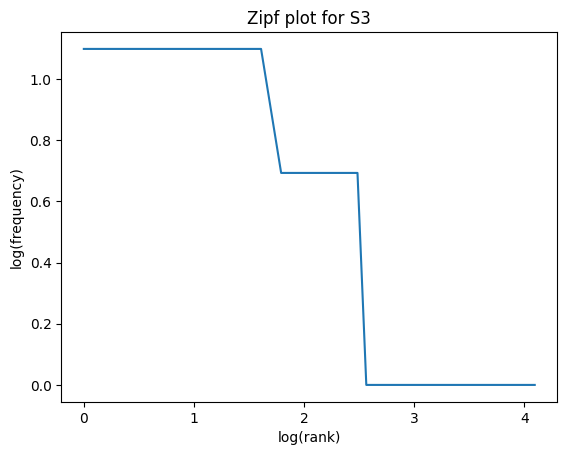

Top 5 bigrams S1: [(('.', 'i'), 7), (('restarting', 'the'), 3), (('i', 'do'), 3), (('do', "n't"), 3), (("n't", 'know'), 3)]
Top 5 bigrams S3: [(("n't", 'know'), 3), (('know', 'changed'), 3), (('student', 'portal'), 2), (('tried', 'restarting'), 2), (('portal', 'keeps'), 1)]


In [ ]:
# Your code
from nltk.stem import PorterStemmer
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

ps = PorterStemmer()

# Assume you already have your tickets processed into tokens
# S1: all tokens
S1 = [tok for r in results for tok in r["Tokens"]]

# S2: no punctuation
S2 = [tok for r in results for tok in r["Tokens"] if tok.isalpha()]

# S3: final tokens (after stopword + punctuation removal)
S3 = [tok for r in results for tok in r["Final"]]

# S4: S3 after Porter stemming
S4 = [ps.stem(tok) for tok in S3]

def corpus_stats(tokens, label):
    unique = set(tokens)
    ttr = len(unique) / len(tokens) if tokens else 0
    print(f"{label}: Tokens={len(tokens)}, Unique={len(unique)}, TTR={ttr:.3f}")

corpus_stats(S1, "S1 (all tokens)")
corpus_stats(S2, "S2 (no punctuation)")
corpus_stats(S3, "S3 (final tokens)")
corpus_stats(S4, "S4 (Porter stemmed)")

# Top 10 words of S1 and S3
print("Top 10 S1:", Counter(S1).most_common(10))
print("Top 10 S3:", Counter(S3).most_common(10))

# Zipf plot for S3
freqs = Counter(S3).most_common()
ranks = np.arange(1, len(freqs)+1)
counts = np.array([f for _, f in freqs])
plt.plot(np.log(ranks), np.log(counts))
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf plot for S3")
plt.show()

# Top 5 bigrams for S1 and S3
def top_bigrams(tokens, label):
    bigrams = [(tokens[i], tokens[i+1]) for i in range(len(tokens)-1)]
    print(f"Top 5 bigrams {label}:", Counter(bigrams).most_common(5))

top_bigrams(S1, "S1")
top_bigrams(S3, "S3")


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*The TTR decreases from S1 to S4 because stemming reduces morphological variation. In S1, many inflected forms (e.g., ‘running’, ‘runs’, ‘ran’) are counted as separate unique tokens. By S4, Porter stemming collapses them into a single stem (‘run’), lowering the number of unique types relative to the total tokens. Thus, the vocabulary appears smaller and the TTR drops.